# 03 · Shopping rhythm: how often do customers come back?

**Business question:** how many customers shop weekly, every two weeks, monthly or less, and how much of the business does each group bring? Which customers are slipping away?

**Data notes (from notebook 01):**
- `days_since_prior_order` is NULL on each user's first order: exclude it.
- The value 30 means "30 days or more" (capped).
- Users have 4–100 orders: customers who left after 1–3 orders are not in the data.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect("../data/instacart.duckdb", read_only=True)

def q(sql):
    """Run a SQL query and return a pandas DataFrame."""
    return con.sql(sql).df()

## 3.1 Each customer's usual rhythm
For every user, compute:
- `n_orders`: number of orders
- `median_gap`: median of `days_since_prior_order` (their "usual" gap between orders)

Write it as a **CTE** called `user_rhythm`, then show the first 10 rows.

In [5]:
q("""
WITH user_rhythm AS(
    SELECT user_id,
        COUNT(*) as n_orders,
        MEDIAN(days_since_prior_order) AS median_gap
    FROM orders
    GROUP BY user_id
)
SELECT *
FROM user_rhythm
ORDER BY user_id
LIMIT 10
""")

,user_id,n_orders,median_gap
0,1,11,19.5
1,2,15,13.0
2,3,13,11.0
3,4,6,19.0
4,5,5,10.5
5,6,4,12.0
6,7,21,7.0
7,8,4,30.0
8,9,4,30.0
9,10,6,23.0


## 3.2 Rhythm segments
Starting from the same CTE, put each user in a segment with `CASE WHEN` on `median_gap`:

| Segment | median_gap |
|---|---|
| 1. Weekly | ≤ 8 days |
| 2. Bi-weekly | 9–15 days |
| 3. Monthly | 16–29 days |
| 4. Infrequent | 30 (= 30 or more) |

Count users per segment and their share (%).

In [12]:
q("""
WITH user_rhythm AS(
    SELECT user_id,
        COUNT(*) as n_orders,
        MEDIAN(days_since_prior_order) AS median_gap
    FROM orders
    GROUP BY user_id
)
SELECT
    CASE 
        WHEN median_gap <= 8 THEN '1.Weekly'
        WHEN median_gap BETWEEN 9 AND 15 THEN '2.Bi-Weekly'
        WHEN median_gap BETWEEN 16 AND 29 THEN '3.Monthly'
        ELSE '4.Infrequent'
    END as segment,
    COUNT(*) AS n_users,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct_users
FROM user_rhythm
GROUP BY segment
ORDER BY segment
""")

,segment,n_users,pct_users
0,1.Weekly,65819,31.9
1,2.Bi-Weekly,54541,26.4
2,3.Monthly,52244,25.3
3,4.Infrequent,33605,16.3


## 3.3 How much business does each segment bring?
For each segment: share of **users** (%) and share of **orders** (%). Save the result as `segments` with columns `segment`, `pct_users`, `pct_orders`.

In [14]:
segments = q("""
WITH user_rhythm AS(
    SELECT user_id,
        COUNT(*) as n_orders,
        MEDIAN(days_since_prior_order) AS median_gap
    FROM orders
    GROUP BY user_id
)
SELECT
    CASE 
        WHEN median_gap <= 8 THEN '1.Weekly'
        WHEN median_gap BETWEEN 9 AND 15 THEN '2.Bi-Weekly'
        WHEN median_gap BETWEEN 16 AND 29 THEN '3.Monthly'
        ELSE '4.Infrequent'
    END as segment,
    COUNT(*) AS n_users,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct_users,
    ROUND(SUM(n_orders) * 100.0 / SUM(SUM(n_orders)) OVER (), 1) AS pct_orders
FROM user_rhythm
GROUP BY segment
ORDER BY segment
""")
segments

,segment,n_users,pct_users,pct_orders
0,1.Weekly,65819,31.9,56.6
1,2.Bi-Weekly,54541,26.4,22.9
2,3.Monthly,52244,25.3,13.7
3,4.Infrequent,33605,16.3,6.7


### Chart: share of users vs share of orders

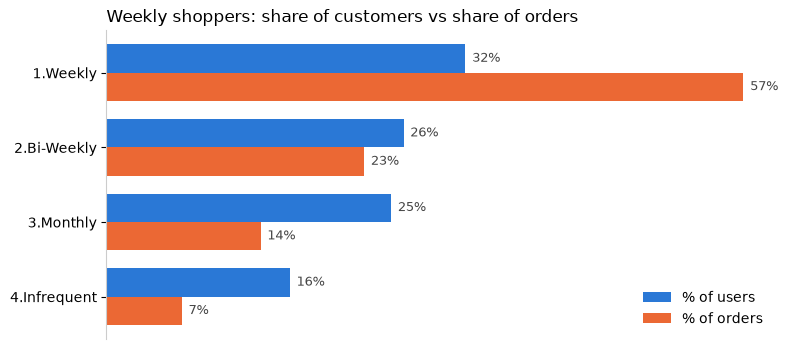

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = range(len(segments))
h = 0.38
ax.barh([i - h/2 for i in y], segments["pct_users"],  height=h, color="#2a78d6", label="% of users")
ax.barh([i + h/2 for i in y], segments["pct_orders"], height=h, color="#eb6834", label="% of orders")

for i, (u, o) in enumerate(zip(segments["pct_users"], segments["pct_orders"])):
    ax.text(u + 0.6, i - h/2, f"{u:.0f}%", va="center", fontsize=9, color="#444")
    ax.text(o + 0.6, i + h/2, f"{o:.0f}%", va="center", fontsize=9, color="#444")

ax.set_yticks(list(y))
ax.set_yticklabels(segments["segment"])
ax.invert_yaxis()
ax.xaxis.set_visible(False)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color("#ccc")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Weekly shoppers: share of customers vs share of orders", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("../figures/rhythm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

Weekly shoppers are 32% of customers but place 57% of orders; weekly + bi-weekly (58% of customers) place 80%. Infrequent customers (16%) place only 7%. Caveats: frequent shoppers mechanically accumulate more orders, and the data has no prices (orders ≠ revenue).

## 3.4 Who is slipping away?
Each user's **last order** is the one with the highest `order_number`. Compare its gap with the user's usual `median_gap`.

A customer is **at risk** if the last gap is at least **2× their usual gap** *and* at least 14 days.

How many customers are at risk, and in which segments?

In [17]:
q("""
WITH user_rhythm AS (
    SELECT user_id,
           COUNT(*) AS n_orders,
           MAX(order_number) AS last_order_number,
           MEDIAN(days_since_prior_order) AS median_gap
    FROM orders
    GROUP BY user_id
),
last_order AS (
    SELECT r.user_id,
           r.median_gap,
           o.days_since_prior_order AS last_gap
    FROM user_rhythm r
    JOIN orders o
      ON o.user_id = r.user_id
     AND o.order_number = r.last_order_number
),
flagged AS (
    SELECT *,
           CASE
               WHEN median_gap <= 8  THEN '1. Weekly'
               WHEN median_gap <= 15 THEN '2. Bi-weekly'
               WHEN median_gap < 30  THEN '3. Monthly'
               ELSE '4. Infrequent'
           END AS segment,
           CASE
               WHEN last_gap >= 2 * median_gap AND last_gap >= 14 THEN 1
               ELSE 0
           END AS at_risk
    FROM last_order
)
SELECT segment,
       COUNT(*)                     AS n_users,
       SUM(at_risk)                 AS n_at_risk,
       ROUND(AVG(at_risk) * 100, 1) AS pct_at_risk
FROM flagged
GROUP BY segment
ORDER BY segment
""")

,segment,n_users,n_at_risk,pct_at_risk
0,1. Weekly,65819,14340.0,21.8
1,2. Bi-weekly,56756,16149.0,28.5
2,3. Monthly,54393,0.0,0.0
3,4. Infrequent,29241,0.0,0.0


## Findings & recommendation

**1. Most customers have a regular rhythm.**
Based on each customer's median gap between orders: 32% shop weekly (≤ 8 days), 26% every two weeks, 25% monthly and 16% less than monthly (median gap of 30+ days).

**2. Weekly shoppers drive the business.**
Weekly customers are 32% of the base but place 57% of all orders, almost 1.8x their share. Weekly and bi-weekly customers together (58% of customers) place 80% of orders, while infrequent customers (16%) place only 7%.

**3. Some regular customers are slipping away.**
30,489 customers (14.8% of all) had a last gap of at least twice their usual rhythm and at least 14 days. The highest share at risk is among bi-weekly customers (28.5%), followed by weekly customers (21.8%). Because `days_since_prior_order` is capped at 30, this rule can only flag weekly and bi-weekly customers: a monthly customer would need a gap of 32+ days, which the data cannot show.

**Recommendation**
For a fixed-route model like Picnic, the biggest lever is frequency, not only acquisition: moving bi-weekly customers to a weekly habit (e.g. recurring "basics" lists or a reminder on their usual delivery day) adds orders on routes that already exist. Customers flagged at risk should get a win-back action as soon as their gap breaks their usual rhythm, before they reach 30+ days.

**Caveats:** frequent shoppers mechanically accumulate more orders; the data has no prices (orders ≠ revenue); customers with fewer than 4 orders are not in the dataset, so real churn is higher.